In [1]:
# 美國升息對台股與新台幣的影響
import os; os.chdir('..') if os.path.basename(os.getcwd())=='notebooks' else None
import duckdb, pandas as pd, numpy as np, statsmodels.api as sm, matplotlib.pyplot as plt, json
con=duckdb.connect(); con.execute(open('sql/clean.sql').read())
df=pd.read_csv('data/processed/monthly_merged.csv',parse_dates=['month']).set_index('month')
df.head()

,taiex_close,usdtwd,ffr,cpi
month,,,,
1997-07-01,10066.349609,28.032273,5.52,160.4
1997-08-01,9827.490234,28.823810,5.54,160.8
1997-09-01,8708.830078,28.731429,5.54,161.2
1997-10-01,7313.399902,29.696364,5.50,161.5
1997-11-01,7797.189941,31.794444,5.52,161.7


In [2]:
df['taiex_ret']=df.taiex_close.pct_change()*100
df['fx_chg']=df.usdtwd.pct_change()*100   # 正值=美元升值/新台幣貶值
df['d_ffr']=df.ffr.diff()
df['cpi_yoy']=df.cpi.pct_change(12)*100
df['regime']=np.where(df.d_ffr>=0.10,'升息',np.where(df.d_ffr<=-0.10,'降息','不動'))
d=df.dropna(subset=['taiex_ret','fx_chg','d_ffr']).copy()
print(d.index.min(),d.index.max(),len(d))
corr=d[['taiex_ret','fx_chg','d_ffr']].corr().round(3); corr

1997-08-01 00:00:00 2026-09-01 00:00:00 350


,taiex_ret,fx_chg,d_ffr
taiex_ret,1.000,-0.293,0.017
fx_chg,-0.293,1.000,0.054
d_ffr,0.017,0.054,1.000


In [3]:
lag=pd.DataFrame({k:{'taiex_ret':d.d_ffr.shift(k).corr(d.taiex_ret),'fx_chg':d.d_ffr.shift(k).corr(d.fx_chg)} for k in range(7)}).T.round(3)
lag.index.name='lag_months'; lag

,taiex_ret,fx_chg
lag_months,,
0,0.017,0.054
1,-0.038,0.022
2,-0.020,-0.003
3,-0.003,-0.031
4,0.012,-0.023
5,-0.008,0.001
6,-0.039,0.060


In [4]:
reg=d.groupby('regime').agg(months=('taiex_ret','size'),taiex_ret_mean=('taiex_ret','mean'),taiex_ret_median=('taiex_ret','median'),taiex_up_ratio=('taiex_ret',lambda x:(x>0).mean()),fx_chg_mean=('fx_chg','mean')).round(3); reg

,months,taiex_ret_mean,taiex_ret_median,taiex_up_ratio,fx_chg_mean
regime,,,,,
不動,241,0.983,1.063,0.585,0.045
升息,62,-0.214,0.381,0.565,0.042
降息,47,0.105,1.152,0.532,0.045


In [5]:
X=sm.add_constant(d[['d_ffr','fx_chg']]); m=sm.OLS(d.taiex_ret,X).fit(cov_type='HC1'); print(m.summary())

                            OLS Regression Results                            
Dep. Variable:              taiex_ret   R-squared:                       0.087
Model:                            OLS   Adj. R-squared:                  0.082
Method:                 Least Squares   F-statistic:                     11.46
Date:                Tue, 13 Oct 2026   Prob (F-statistic):           1.51e-05
Time:                        11:57:32   Log-Likelihood:                -1132.4
No. Observations:                 350   AIC:                             2271.
Df Residuals:                     347   BIC:                             2282.
Df Model:                           2                                         
Covariance Type:                  HC1                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.7223      0.326      2.213      0.0

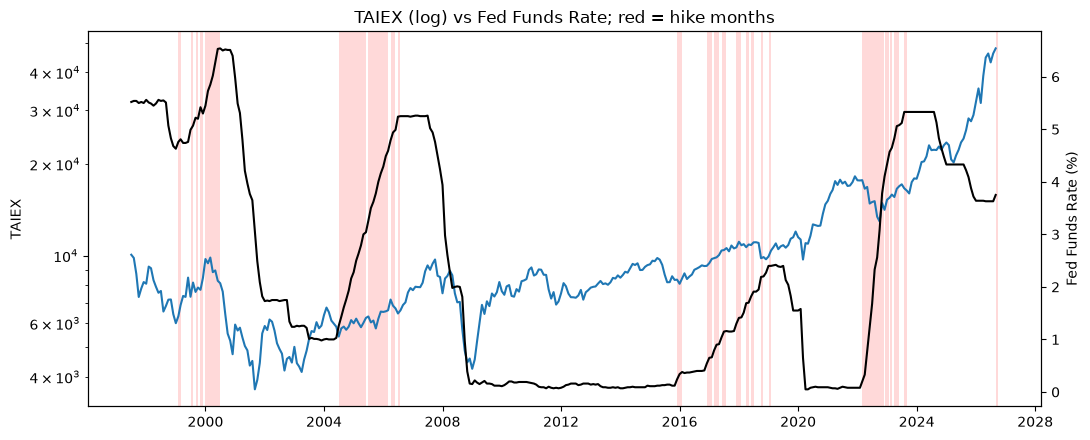

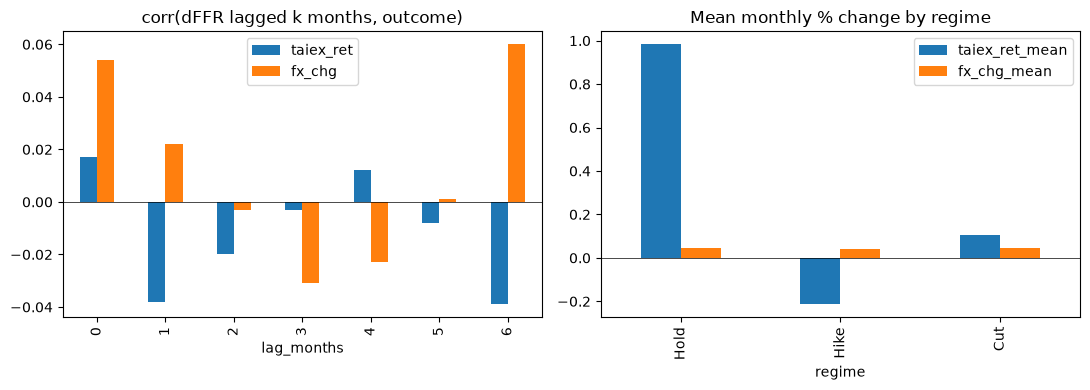

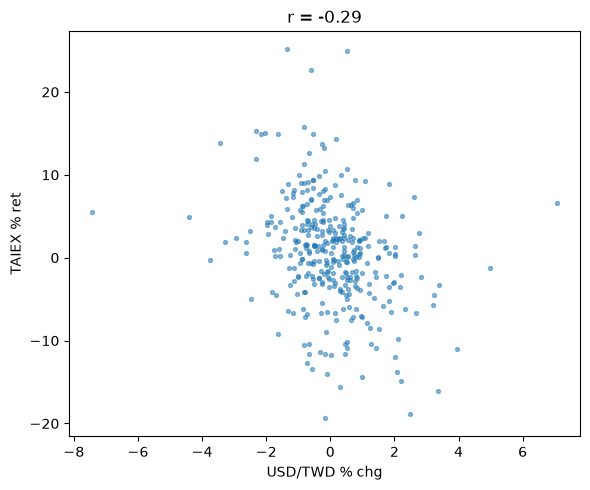

In [6]:
os.makedirs('outputs',exist_ok=True)
fig,ax=plt.subplots(figsize=(11,4.5)); ax.plot(df.index,df.taiex_close,color='tab:blue'); ax.set_ylabel('TAIEX'); ax.set_yscale('log')
for t in d.index[d.regime=='升息']: ax.axvspan(t,t+pd.offsets.MonthEnd(1),color='red',alpha=.15,lw=0)
ax2=ax.twinx(); ax2.plot(df.index,df.ffr,color='black'); ax2.set_ylabel('Fed Funds Rate (%)')
ax.set_title('TAIEX (log) vs Fed Funds Rate; red = hike months'); fig.tight_layout(); fig.savefig('outputs/01_taiex_vs_ffr.png',dpi=150)
fig,ax=plt.subplots(1,2,figsize=(11,4)); lag.plot.bar(ax=ax[0]); ax[0].axhline(0,color='k',lw=.5); ax[0].set_title('corr(dFFR lagged k months, outcome)')
reg[['taiex_ret_mean','fx_chg_mean']].rename(index={'升息':'Hike','降息':'Cut','不動':'Hold'}).plot.bar(ax=ax[1]); ax[1].axhline(0,color='k',lw=.5); ax[1].set_title('Mean monthly % change by regime')
fig.tight_layout(); fig.savefig('outputs/02_lag_and_regime.png',dpi=150)
fig,ax=plt.subplots(figsize=(6,5)); ax.scatter(d.fx_chg,d.taiex_ret,s=8,alpha=.5); ax.set_xlabel('USD/TWD % chg'); ax.set_ylabel('TAIEX % ret'); ax.set_title(f'r = {d.fx_chg.corr(d.taiex_ret):.2f}'); fig.tight_layout(); fig.savefig('outputs/03_fx_vs_taiex.png',dpi=150)

In [7]:
t=df.reset_index()[['month','taiex_close','taiex_ret','usdtwd','fx_chg','ffr','d_ffr','cpi_yoy','regime']].round(4)
t.to_csv('outputs/tableau_monthly.csv',index=False,encoding='utf-8-sig'); lag.to_csv('outputs/lag_correlation.csv'); reg.to_csv('outputs/regime_summary.csv',encoding='utf-8-sig')
res={'period':[str(d.index.min().date()),str(d.index.max().date())],'n':len(d),'corr':corr.to_dict(),'lag':lag.to_dict(),'regime':reg.to_dict(),'ols':{'params':m.params.round(4).to_dict(),'pvalues':m.pvalues.round(4).to_dict(),'r2':round(m.rsquared,4)}}
json.dump(res,open('outputs/results.json','w'),ensure_ascii=False,indent=1,default=str); print(json.dumps(res,ensure_ascii=False,default=str))

{"period": ["1997-08-01", "2026-09-01"], "n": 350, "corr": {"taiex_ret": {"taiex_ret": 1.0, "fx_chg": -0.293, "d_ffr": 0.017}, "fx_chg": {"taiex_ret": -0.293, "fx_chg": 1.0, "d_ffr": 0.054}, "d_ffr": {"taiex_ret": 0.017, "fx_chg": 0.054, "d_ffr": 1.0}}, "lag": {"taiex_ret": {"0": 0.017, "1": -0.038, "2": -0.02, "3": -0.003, "4": 0.012, "5": -0.008, "6": -0.039}, "fx_chg": {"0": 0.054, "1": 0.022, "2": -0.003, "3": -0.031, "4": -0.023, "5": 0.001, "6": 0.06}}, "regime": {"months": {"不動": 241, "升息": 62, "降息": 47}, "taiex_ret_mean": {"不動": 0.983, "升息": -0.214, "降息": 0.105}, "taiex_ret_median": {"不動": 1.063, "升息": 0.381, "降息": 1.152}, "taiex_up_ratio": {"不動": 0.585, "升息": 0.565, "降息": 0.532}, "fx_chg_mean": {"不動": 0.045, "升息": 0.042, "降息": 0.045}}, "ols": {"params": {"const": 0.7223, "d_ffr": 1.1871, "fx_chg": -1.4115}, "pvalues": {"const": 0.0269, "d_ffr": 0.6803, "fx_chg": 0.0}, "r2": 0.087}}


/tmp/ipykernel_58375/2879534569.py:1: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  t=df.reset_index()[['month','taiex_close','taiex_ret','usdtwd','fx_chg','ffr','d_ffr','cpi_yoy','regime']].round(4)
